Problem 5

I need some necessary libraries:

A way to manipulate numbers: numpy

A way to manipulate structured data: pandas

A way to plot data: matplotlib

A way to use ML tools: torch, sklearn

In [1]:
%pip install --upgrade --force-reinstall --no-deps --no-cache-dir git+https://github.com/golddragongh/golddragon.git

%pip install onnx onnxruntime onnxscript

  Cloning https://github.com/golddragongh/golddragon.git to /tmp/pip-req-build-wc2jhbsn
  Running command git clone --filter=blob:none --quiet https://github.com/golddragongh/golddragon.git /tmp/pip-req-build-wc2jhbsn
  Resolved https://github.com/golddragongh/golddragon.git to commit 81c04cdd282fe48a5d7782d07759b3c0d78d37c4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for golddragon: filename=golddragon-0.1.5-cp39-abi3-linux_x86_64.whl size=236717 sha256=aaeb9bf03f261d45e1d80723757ed4dc85fe28b57a59f26072480ded681f20eb
  Stored in directory: /tmp/pip-ephem-wheel-cache-kjaidgnj/wheels/87/bc/30/77768b6697d8e91c1cb3a05e673259faab570c7b627f677d02
Successfully built golddragon
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 110.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 104.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━

1.) Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

import onnx
from sklearn.model_selection import train_test_split
from golddragon.model.neuralnet import TorchNet

2.) Load the Dataset

In [3]:
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/Diabetes/diabetes.csv"
df = pd.read_csv(url)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


3.) Supervised; Seperate label from the features

In [4]:
x = df.drop(columns=["Outcome"])
y = df["Outcome"]

4.) Seperate training and testing data

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1,stratify=y)

5.) Initialize the neural network

In [6]:
torch.manual_seed(1)
model = TorchNet(input_dim=8, output_dim=1)
print(model)

TorchNet(
  (layer1): Linear(in_features=8, out_features=4, bias=True)
  (layer2): Linear(in_features=4, out_features=3, bias=True)
  (layer3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
)


6.) Standardize the data

In [7]:
x_train_standard = model.standardize(x_train, fit=True)
x_test_standard = model.standardize(x_test, fit=False)

7.) Standardize

In [8]:
X_train = torch.tensor(x_train_standard, dtype=torch.float32)

Y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)

X_test = torch.tensor(x_test_standard, dtype=torch.float32)

Y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

print(X_train.shape)
print(Y_train.shape)
print(X_test.shape)
print(Y_test.shape)

torch.Size([614, 8])
torch.Size([614, 1])
torch.Size([154, 8])
torch.Size([154, 1])


8.) Train

In [9]:
loss_history = model.fit_model(X_train, Y_train, epochs=1000, lr=0.01)

Epoch 100, Loss: 0.467320
Epoch 200, Loss: 0.439169
Epoch 300, Loss: 0.424707
Epoch 400, Loss: 0.421616
Epoch 500, Loss: 0.416839
Epoch 600, Loss: 0.415341
Epoch 700, Loss: 0.413162
Epoch 800, Loss: 0.412436
Epoch 900, Loss: 0.411878
Epoch 1000, Loss: 0.411773


9.) Plot the loss

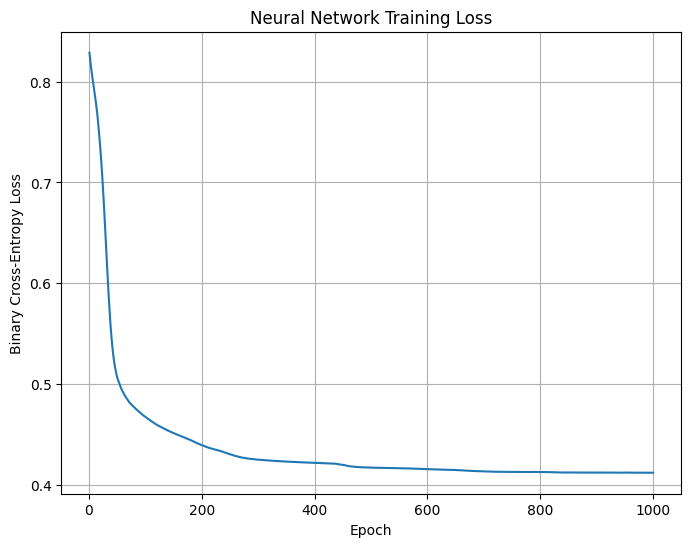

Initial Loss: 0.8287568092346191
Final Loss: 0.41177329421043396


In [10]:
model.plot_loss()

print("Initial Loss:", loss_history[0])
print("Final Loss:", loss_history[-1])

10.) Evaluate the model

In [11]:
model.eval()

with torch.no_grad():

    logits = model(X_test)

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= 0.5).float()

    accuracy = (predictions == Y_test).float().mean()

    test_loss = nn.BCEWithLogitsLoss()(logits, Y_test)

print("Testing Accuracy:", accuracy.item() * 100, "%")
print("Testing Loss:", test_loss.item())

Testing Accuracy: 74.02597665786743 %
Testing Loss: 0.5168595314025879


11.) Save the trained model

In [12]:
model.save_onnx("diabetes_model.onnx")
onnx_model = onnx.load("diabetes_model.onnx")
onnx.checker.check_model(onnx_model)
print("ONNX model is valid")

Model successfully exported to ONNX
ONNX model is valid


12.) Load the trained model

In [13]:
model.load_onnx("diabetes_model.onnx")

ONNX model successfully loaded


13.) Prepare teh input data

In [14]:
new_sample = pd.DataFrame([[7, 149, 73, 94, 94, 32, 0.672, 45]], columns=x_train.columns)
new_sample

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,7,149,73,94,94,32,0.672,45


14.) Predict

In [15]:
probability, prediction = model.predict_onnx(new_sample)
print("Predicted Probability:", probability.item())
print("Predicted Outcome:", prediction.item())

Predicted Probability: 0.1135740727186203
Predicted Outcome: 0
